In [1]:
import geopandas as gpd
import folium
print("Siap!")

Siap!


In [2]:
import os 
print(os.listdir("../data"))

['DLBA_Owned_Properties_3248658804103307609.geojson']


In [10]:
import geopandas as gpd
gdf = gpd.read_file("../data/dlba_owned.geojson")
print ("jumlah baris dan kolom:", gdf.shape)
print("sistem koordinat:", gdf.crs)
print(gdf.columns.tolist())
gdf.head()

jumlah baris dan kolom: (55690, 14)
sistem koordinat: EPSG:3857
['name', 'parcel_id', 'inventory_status_socrata', 'neighborhood', 'council_district', 'street_number', 'street_direction', 'street_name', 'street_type', 'block_range', 'longitude', 'latitude', 'ObjectId', 'geometry']


,name,parcel_id,inventory_status_socrata,neighborhood,council_district,street_number,street_direction,street_name,street_type,block_range,longitude,latitude,ObjectId,geometry
0,12217 Longacre,22070660.,Neighborhood Lot For Sale,Plymouth-I96,7.0,12217.0,NaN,LONGACRE,St,12200-12270 Longacre St,-83.214971,42.377080,1,POINT (-9263448.22 5217632.584)
1,156 E GREENDALE,01005920.,Neighborhood Lot For Sale,Greenfield Park,3.0,156.0,E,GREENDALE,St,2-598 E Greendale St,-83.099095,42.426765,2,POINT (-9250548.955 5225122.764)
2,7226 Gould,18009166.,DLBA Owned Lot,Delray,6.0,7226.0,NaN,GOULD,St,7200-7399 Gould St,-83.109399,42.296171,3,POINT (-9251695.971 5205448.181)
3,10035 Orangelawn,18006071.,DLBA Owned Structure,Barton-McFarland,7.0,10035.0,NaN,ORANGELAWN,St,10000-10299 Orangelawn St,-83.159112,42.368855,4,POINT (-9257230.044 5216393.255)
4,14158 Steel,22022277.,DLBA Owned Lot,Happy Homes,7.0,14158.0,NaN,STEEL,St,14100-14199 Steel St,-83.170752,42.391003,5,POINT (-9258525.709 5219730.883)


In [8]:
import os
os.rename(
    "../data/DLBA_Owned_Properties_3248658804103307609.geojson",
    "../data/dlba_owned.geojson",
)

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

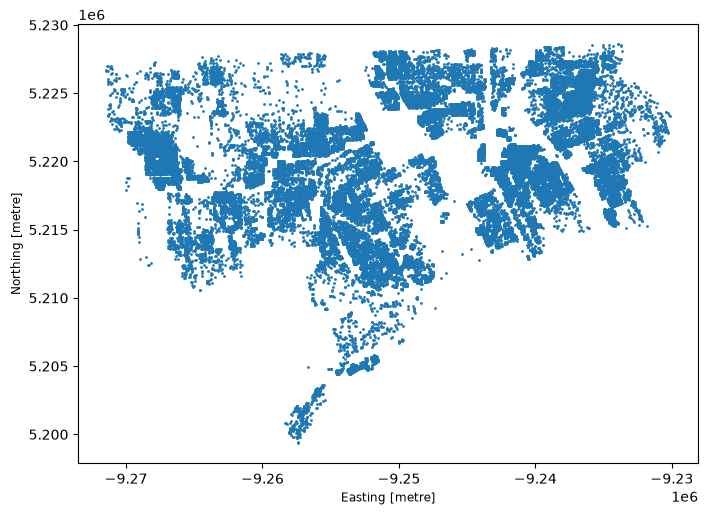

In [11]:
gdf.plot(markersize=1,figsize=(8,8))

In [15]:
print("jumlah baris:", len(gdf))
print()

for col in gdf.columns:
    if gdf[col].dtype == "object" and gdf[col].nunique() <= 15:
        print("=== Kolom:", col, "===")
        print(gdf[col].value_counts(dropna=False))
        print()

jumlah baris: 55690



In [16]:
print(gdf.columns.tolist())
gdf.head(3)

['name', 'parcel_id', 'inventory_status_socrata', 'neighborhood', 'council_district', 'street_number', 'street_direction', 'street_name', 'street_type', 'block_range', 'longitude', 'latitude', 'ObjectId', 'geometry']


,name,parcel_id,inventory_status_socrata,neighborhood,council_district,street_number,street_direction,street_name,street_type,block_range,longitude,latitude,ObjectId,geometry
0,12217 Longacre,22070660.,Neighborhood Lot For Sale,Plymouth-I96,7.0,12217.0,NaN,LONGACRE,St,12200-12270 Longacre St,-83.214971,42.377080,1,POINT (-9263448.22 5217632.584)
1,156 E GREENDALE,01005920.,Neighborhood Lot For Sale,Greenfield Park,3.0,156.0,E,GREENDALE,St,2-598 E Greendale St,-83.099095,42.426765,2,POINT (-9250548.955 5225122.764)
2,7226 Gould,18009166.,DLBA Owned Lot,Delray,6.0,7226.0,NaN,GOULD,St,7200-7399 Gould St,-83.109399,42.296171,3,POINT (-9251695.971 5205448.181)


In [17]:
print("CRS:", gdf.crs)
print("Jumlah baris:", len(gdf))
print()
print(gdf["inventory_status_socrata"].value_counts(dropna=False))

CRS: EPSG:3857
Jumlah baris: 55690

inventory_status_socrata
Neighborhood Lot For Sale                 26934
DLBA Owned Lot                            23761
DLBA Owned Structure                       1718
Side Lot For Sale                          1508
Marketed Lot For Sale                      1005
Improved Lot For Sale                       247
Accessory Structure Lot For Sale            197
Oversized Lot For Sale                      140
Marketed Structure For Sale                 121
Own It Now Structure For Sale                18
Renovation Programs Structure For Sale       16
IHOA Side Lot For Sale                       11
Create-a-Project For Sale                     6
Auction Structure For Sale                    5
Own It Now Lot For Sale                       1
Renovation Programs Lot For Sale              1
Auction Lot For Sale                          1
Name: count, dtype: int64


In [18]:
lots = gdf[
    gdf["inventory_status_socrata"].str.contains("lot", case=False, na=False)
].copy()

print("Sebelum disaring:", len(gdf))
print("Sesudah disaring:", len(lots))
print()
print(lots["inventory_status_socrata"].value_counts())

Sebelum disaring: 55690
Sesudah disaring: 53806

inventory_status_socrata
Neighborhood Lot For Sale           26934
DLBA Owned Lot                      23761
Side Lot For Sale                    1508
Marketed Lot For Sale                1005
Improved Lot For Sale                 247
Accessory Structure Lot For Sale      197
Oversized Lot For Sale                140
IHOA Side Lot For Sale                 11
Own It Now Lot For Sale                 1
Renovation Programs Lot For Sale        1
Auction Lot For Sale                    1
Name: count, dtype: int64


In [19]:
keep_status = [
    "Neighborhood Lot For Sale",
    "DLBA Owned Lot",
    "Marketed Lot For Sale",
    "Oversized Lot For Sale",
    "Own It Now Lot For Sale",
    "Auction Lot For Sale",
    "Renovation Programs Lot For Sale",
]

lots = gdf[gdf["inventory_status_socrata"].isin(keep_status)].copy()

print("Sebelum disaring:", len(gdf))
print("Sesudah disaring:", len(lots))
print("Geometri kosong:", lots.geometry.isna().sum())
print("Parcel ID dobel:", lots["parcel_id"].duplicated().sum())

Sebelum disaring: 55690
Sesudah disaring: 51843
Geometri kosong: 0
Parcel ID dobel: 0


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

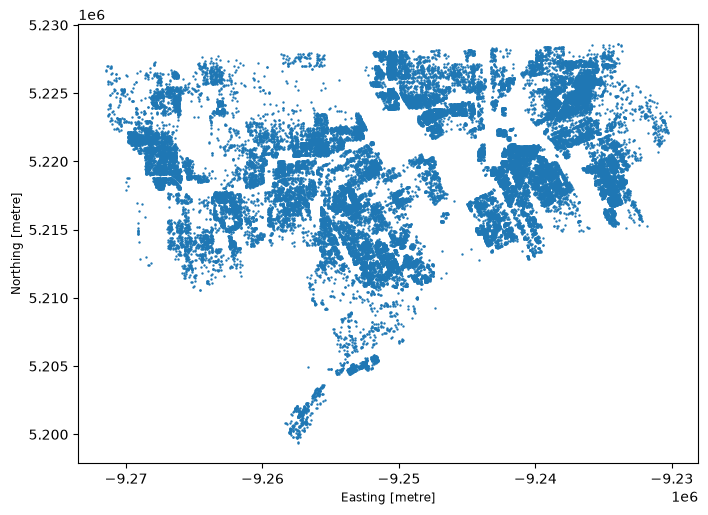

In [20]:
lots.to_file("../data/lots_filtered.geojson", driver="GeoJSON")
lots.plot(markersize=0.5, figsize=(8, 8))